In [1]:
import time
import datetime

print(datetime.datetime.now())

#while datetime.datetime.now().hour != 3 or datetime.datetime.now().minute != 0:
#    time.sleep(30)

2024-11-18 09:18:58.496163


In [2]:
!pip install -r requirements.txt

In [3]:
import os
#os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

In [4]:
from train.loader import Dataset

scale_factor = 1
loaded = {}

dataset = Dataset()
dataset.load_data()

stats = dataset.get_stats()
print(stats)

resample = True

if resample:

    dataset.resample(class_size=2000)
    
    stats = dataset.get_stats()
    print(stats)

dataset.split_train_test(test_size=0.15)

  0%|          | 0/21377 [00:00<?, ?it/s]/opt/conda/lib/python3.12/site-packages/rasterio/__init__.py:355: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
100%|██████████| 21377/21377 [00:57<00:00, 369.23it/s]


{'Building': 4689, 'Small car': 4290, 'Truck': 2746, 'Cargo plane': 635, 'Storage tank': 1469, 'Bus': 2155, 'Shipping container': 1523, 'Motorboat': 1069, 'Dump truck': 1236, 'Excavator': 789, 'Fishing vessel': 706, 'Helicopter': 70}
{'Cargo plane': 2000, 'Helicopter': 2000, 'Small car': 2000, 'Bus': 2000, 'Truck': 2000, 'Motorboat': 2000, 'Fishing vessel': 2000, 'Dump truck': 2000, 'Excavator': 2000, 'Building': 2000, 'Storage tank': 2000, 'Shipping container': 2000}
Number of training images: 20400
Number of validation images: 3600


2024-11-18 09:20:04.759758: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-11-18 09:20:04.776696: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-11-18 09:20:04.781773: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-11-18 09:20:04.797669: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-11-18 09:20:05.985949: W tensorflow/compiler/tf2

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness               │ (None, 224, 224, 3)    │             0 │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_crop (RandomCrop)        │ (None, 212, 212, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 12)             │    23,589,388 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,388 (89.99 MB)

 Trainable params: 23,543,948 (89.81 MB)

 Non-trainable params: 45,440 (177.50 KB)

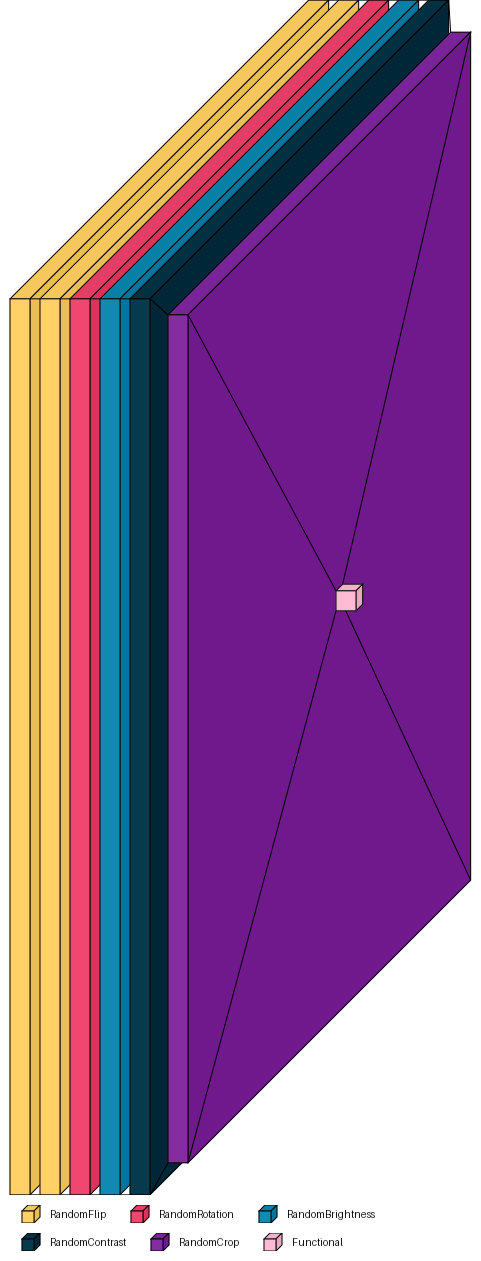

In [5]:
import time
import visualkeras

from tensorflow.keras.optimizers import Adam, AdamW, SGD, RMSprop
from tensorflow.keras.losses import CategoricalCrossentropy, SparseCategoricalCrossentropy
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, Activation, Flatten, BatchNormalization, Conv2D, MaxPooling2D, ZeroPadding2D, SpatialDropout2D
from tensorflow.keras.layers import RandomFlip, RandomContrast, RandomBrightness, RandomCrop, RandomRotation
from tensorflow.keras.activations import relu, softmax
from tensorflow.keras.optimizers.schedules import CosineDecay
from keras.applications import ResNet50V2

from keras import backend as K
import gc

from train.experiment import Experiment

name = f"resnet50_resample_aug{str(int(time.time()))}"
folder = f"experiments_cnn/{name}-{str(int(time.time()))}"

name = "resnet50_resample_aug1731701140"
folder = "experiments_cnn/resnet50_resample_aug1731701140-1731701140"

parameters = {
    "batch_size": 256,
    "epochs": 5000
}

model = Sequential()
model.add(Input(shape=(224,224,3)))

augmentation = True

if augmentation:
    
    model.add(RandomFlip('horizontal'))
    model.add(RandomFlip('vertical'))
    model.add(RandomRotation(1))
    model.add(RandomBrightness(1))
    model.add(RandomContrast(1))
    model.add(RandomCrop(212, 212))
    
    resnet = ResNet50V2(
        include_top=True,
        weights=None,
        input_tensor=None,
        input_shape=(212,212,3),
        pooling=None,
        classes=12,
        classifier_activation="softmax",
        name="resnet50",
    )

else:
    
    resnet = ResNet50V2(
        include_top=True,
        weights=None,
        input_tensor=None,
        input_shape=(224,224,3),
        pooling=None,
        classes=12,
        classifier_activation="softmax",
        name="resnet50",
    )

model.add(resnet)
model.summary()

base_lr = 0.01
opt = AdamW(learning_rate=base_lr, beta_1=0.9, beta_2=0.999, epsilon=1e-8, amsgrad=True, clipnorm=1.0)
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

visualkeras.layered_view(model, legend=True, to_file='./resnet50.png')

In [6]:
experiment = Experiment(name, folder, parameters, model)

In [7]:
from train.trainer import Trainer

trainer = Trainer(dataset, experiment)
#trainer.default_callbacks()
trainer.enable_lr_plateau(50)
trainer.enable_early_stop(200)
trainer.enable_tensorboard()
trainer.enable_tqdm()
trainer.enable_checkpoints()

#results = trainer.train()

In [8]:
#trainer.validate()

In [9]:
trainer.test()

0it [00:00, ?it/s]/opt/conda/lib/python3.12/site-packages/rasterio/__init__.py:355: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
1it [00:06,  6.80s/it]


Number of testing images: 2635


/opt/conda/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:719: UserWarning: Skipping variable loading for optimizer 'adamw', because it has 2 variables whereas the saved optimizer has 524 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
2635it [04:26,  9.89it/s]
